# Dominant caption, per-tile effect, short answers, transfer to 500M and 2.2B

Uses the saved perturbation **v** (no training). All perturbed images go through the **real pipeline** (v added to the image, saved as 8-bit, standard processor), except part E, which adds v after preprocessing (as in training) for comparison with notebook 02.

| Part | Question | Images |
|---|---|---|
| C | Do perturbed captions collapse onto one "dominant caption"? (every caption is saved) | 200 |
| D | With image splitting on, which tiles carry the attack: the global tile or the local ones? | 50 |
| E | Short answers: a better metric than text similarity (shared content words) | 100 |
| F | Transfer: does the same v fool SmolVLM-500M (same encoder) and SmolVLM-2.2B (different encoder)? | 200 / 100 |

Each part prints its results as soon as it finishes and saves them, so a crash later does not lose earlier results. The last section draws the figures.

**Before running:** T4 GPU, then `Run all`. Rough estimate: 30–45 min, most of it in part F (the 2.2B model is the slow one).

**Outputs:** the printed results of every part (C, D, E, F) and the figures, saved to `tiles_transfer_results.json` and `tiles_transfer_figures.png`.

## 1. Configuration

In [1]:
MODELS = {
    "256M": "HuggingFaceTB/SmolVLM-256M-Instruct",   # v was built on this one
    "500M": "HuggingFaceTB/SmolVLM-500M-Instruct",   # same vision encoder (SigLIP-B/16, 512 px)
    "2.2B": "HuggingFaceTB/SmolVLM-Instruct",        # different encoder (SigLIP-SO400M)
}
IMG_SIZE  = 512
N_BUILD   = 500          # skipped: these images built v
N_DOM     = 200          # part C
N_TILES   = 50           # part D
N_SHORT   = 100          # part E
N_TR_500M = 200          # part F
N_TR_2B   = 100          # part F (slow)
NORM_XI   = 10/255
V_PATH    = "/content/drive/MyDrive/uap_smolvlm/uap_smolvlm256m_linf10.npy"
OUT_DIR   = "/content/drive/MyDrive/uap_smolvlm"
CAPTION_SIM_CHANGED = 0.5
MAX_NEW_TOKENS = 40
P_DESCRIBE = "Describe this image in one sentence."
P_SHORT    = "What is the main object in this picture? Answer in a few words."
SEED = 0

## 2. Setup and data

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import time, json, glob, random, tarfile, re, gc
from pathlib import Path
from collections import Counter
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")
DEVICE = "cuda"; assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path(OUT_DIR)

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR = DATA_DIR / "imagenetv2-matched-frequency.tar.gz"
if not list(DATA_DIR.glob("imagenetv2-*/")):
    !wget -q --show-progress -O {TAR} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz
    with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)
    TAR.unlink()
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
perm = np.random.RandomState(SEED).permutation(len(FILES))
n_eval = max(N_DOM, N_TILES, N_SHORT, N_TR_500M, N_TR_2B)
files_eval = [FILES[i] for i in perm[N_BUILD:N_BUILD + n_eval]]          # same held-out images as before
PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
E_u8 = torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(files_eval, desc="decoding")])

v = torch.from_numpy(np.load(V_PATH)).float()          # kept on CPU, (1,3,512,512) in [0,1] units
torch.manual_seed(SEED)
v_rand = NORM_XI * torch.sign(torch.randn_like(v))
PERTS = {"universal v": v, "random ±ξ": v_rand}
print("v:", tuple(v.shape), "||v||_inf =", round(v.abs().max().item() * 255, 2), "/255")

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def text_sim(a, b):
    ea = st.encode(a, convert_to_tensor=True, normalize_embeddings=True)
    eb = st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu()

RES = {}
def save():
    with open(OUT / "tiles_transfer_results.json", "w") as f:
        json.dump(RES, f, indent=1, default=float)

Mounted at /content/drive
/content/data/image 100%[===================>]   1.18G   100MB/s    in 16s     


/tmp/ipykernel_3305/608836450.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)


decoding:   0%|          | 0/200 [00:00<?, ?it/s]

v: (1, 3, 512, 512) ||v||_inf = 10.0 /255


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

... (7 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 3. Model and pipeline helpers

In [3]:
from transformers import AutoProcessor, AutoModelForImageTextToText

def load(key, dtype):
    proc = AutoProcessor.from_pretrained(MODELS[key]); proc.tokenizer.padding_side = "left"
    mdl = AutoModelForImageTextToText.from_pretrained(MODELS[key], torch_dtype=dtype).to(DEVICE).eval()
    for p in mdl.parameters(): p.requires_grad_(False)
    ip = proc.image_processor
    print(f"Loaded {key}: dtype {dtype}, max_image_size {getattr(ip, 'max_image_size', None)}, "
          f"vision params {sum(p.numel() for p in mdl.model.vision_model.parameters())/1e6:.0f}M")
    return proc, mdl

def unload(*objs):
    for o in objs: del o
    gc.collect(); torch.cuda.empty_cache()

def chat(proc, prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return proc.apply_chat_template(msgs, add_generation_prompt=True)

def to_pil_u8(u8, pert=None):
    # Real pipeline: add v in pixel space, then save as an 8-bit image
    x = u8.float()
    if pert is not None: x = x + pert[0] * 255
    return Image.fromarray(x.round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy())

def to_dev(batch, dtype):
    return {k: (t.to(DEVICE, dtype) if t.is_floating_point() else t.to(DEVICE)) for k, t in batch.items()}

@torch.no_grad()
def gen_pipeline(proc, mdl, u8s, prompt, pert, split, bs=8):
    dtype = next(mdl.parameters()).dtype; outs, tiles = [], None
    for i in range(0, len(u8s), bs):
        pils = [to_pil_u8(u, pert) for u in u8s[i:i+bs]]
        inp = to_dev(proc(text=[chat(proc, prompt)] * len(pils), images=[[p] for p in pils],
                          do_image_splitting=split, return_tensors="pt", padding=True), dtype)
        tiles = inp["pixel_values"].shape[1]
        g = mdl.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += proc.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs], tiles

@torch.no_grad()
def tile_cosines(proc, mdl, u8s, pert, split):
    # (n_images, n_tiles): visual-token cosine, clean vs perturbed, per tile, both through the standard processor
    dtype = next(mdl.parameters()).dtype; VIS = mdl.model.vision_model; rows = []
    for u in u8s:
        z = []
        for p in (None, pert):
            px = proc.image_processor(images=[[to_pil_u8(u, p)]], do_image_splitting=split, return_tensors="pt")["pixel_values"][0]
            z.append(VIS(pixel_values=px.to(DEVICE, dtype)).last_hidden_state.float())
        rows.append(F.cosine_similarity(z[0], z[1], dim=-1).mean(dim=1).cpu())
    return torch.stack(rows)

def changed_stats(c0, c1):
    sim = text_sim(c0, c1)
    return {"changed": (sim < CAPTION_SIM_CHANGED).float().mean().item(), "mean_sim": sim.mean().item()}

## 4. Part C — Dominant caption (256M, real pipeline, splitting off)

In [4]:
t0 = time.time()
proc, mdl = load("256M", torch.float32)
u8s = E_u8[:N_DOM]
caps = {"clean": gen_pipeline(proc, mdl, u8s, P_DESCRIBE, None, False)[0]}
for name, pert in PERTS.items():
    caps[name] = gen_pipeline(proc, mdl, u8s, P_DESCRIBE, pert, False)[0]

OPENER = re.compile(r"^(in this (image|picture)|this image (shows|is))[, ]*((i|we) can see|there (is|are)|we see)?[, ]*")
def norm_cap(s): return OPENER.sub("", re.sub(r"[^a-z0-9 ,]", "", s.lower()).strip()).strip(" ,")
STOP = set("a an the of on in and with is are at to its it this that there some two one we can see i image picture which who".split())
def words(s): return [w for w in re.findall(r"[a-z]+", s.lower()) if w not in STOP and len(w) > 2]

dom = {}
for name in ["clean", "universal v", "random ±ξ"]:
    nc = Counter(norm_cap(c) for c in caps[name])
    wc = Counter(w for c in caps[name] for w in set(words(c)))
    dom[name] = {"distinct_captions": len(nc), "top_captions": nc.most_common(5), "top_words": wc.most_common(10)}
person = {n: float(np.mean(["person" in c.lower() or "man " in c.lower() or "woman" in c.lower() for c in caps[n]])) for n in caps}
RES["C_dominant"] = {"n": N_DOM, "summary": dom, "mentions_person": person, "all_captions": caps}; save()

print(f"PART C — {N_DOM} held-out images, real pipeline, splitting off ({(time.time()-t0)/60:.1f} min)\n")
for name in ["clean", "universal v", "random ±ξ"]:
    d = dom[name]
    print(f"[{name}]  distinct captions: {d['distinct_captions']}/{N_DOM}   mention a person: {person[name]:.0%}")
    for c, k in d["top_captions"]: print(f"   {k:4d} x  {c[:90]}")
    print("   top words (share of captions):", ", ".join(f"{w} {k/N_DOM:.0%}" for w, k in d["top_words"][:8]))
    print()

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

Loaded 256M: dtype torch.float32, max_image_size {'longest_edge': 512}, vision params 86M
PART C — 200 held-out images, real pipeline, splitting off (3.3 min)

[clean]  distinct captions: 189/200   mention a person: 14%
      7 x  a dog
      3 x  a few objects
      2 x  a bird on the branch of a tree
      2 x  a monkey
      2 x  a bird standing on the ground
   top words (share of captions): background 12%, standing 11%, person 11%, dog 10%, ground 10%, holding 10%, trees 8%, objects 7%

[universal v]  distinct captions: 173/200   mention a person: 28%
      8 x  a person wearing a white shirt and black pant
      5 x  a person wearing a white shirt
      3 x  a person wearing a white shirt and a black jacket
      3 x  the text on the left side
      3 x  a table with a few things on it
   top words (share of captions): person 28%, wearing 18%, white 17%, shirt 14%, black 12%, pant 6%, text 6%, people 6%

[random ±ξ]  distinct captions: 179/200   mention a person: 14%
      8 x  a

## 5. Part D — Which tiles carry the attack? (256M, splitting on)

In [5]:
t0 = time.time()
cos = {name: tile_cosines(proc, mdl, E_u8[:N_TILES], pert, True) for name, pert in PERTS.items()}
n_t = cos["universal v"].shape[1]
RES["D_tiles"] = {"n": N_TILES, "n_tiles": n_t, "note": "last tile = global (downscaled whole image), others = local tiles, row-major",
                  "mean_cos_per_tile": {k: c.mean(0).tolist() for k, c in cos.items()}}; save()

print(f"PART D — {N_TILES} images, {n_t} tiles each ({(time.time()-t0)/60:.1f} min)")
print("Mean visual-token cosine, clean vs perturbed (lower = more damage). Last tile = global view.\n")
for name, c in cos.items():
    m = c.mean(0)
    print(f"[{name}]  local tiles mean {m[:-1].mean():.3f} (min {m[:-1].min():.3f}, max {m[:-1].max():.3f})   GLOBAL tile {m[-1]:.3f}")
    side = int(round((n_t - 1) ** 0.5))
    if side * side == n_t - 1:
        for r in range(side): print("     " + "  ".join(f"{x:.2f}" for x in m[r*side:(r+1)*side].tolist()))
    print()

PART D — 50 images, 17 tiles each (4.5 min)
Mean visual-token cosine, clean vs perturbed (lower = more damage). Last tile = global view.

[universal v]  local tiles mean 0.723 (min 0.681, max 0.750)   GLOBAL tile 0.142
     0.72  0.68  0.71  0.72
     0.75  0.73  0.71  0.74
     0.72  0.71  0.72  0.75
     0.73  0.71  0.72  0.75

[random ±ξ]  local tiles mean 0.771 (min 0.751, max 0.784)   GLOBAL tile 0.865
     0.78  0.78  0.78  0.78
     0.78  0.76  0.76  0.77
     0.77  0.75  0.76  0.76
     0.78  0.77  0.77  0.78



## 6. Part E — Short answers with a content-word metric (256M)

In [6]:
# Same as notebook 02, part A ('main object'), but through the real pipeline, and with a second metric:
# the answer counts as unchanged if clean and perturbed answers share at least one content word ("dog" vs "a white dog").
def content(s): return {w[:-1] if w.endswith("s") and len(w) > 3 else w for w in words(s)}
t0 = time.time()
u8s = E_u8[:N_SHORT]
a0 = gen_pipeline(proc, mdl, u8s, P_SHORT, None, False)[0]
short = {"clean_answers": a0}
for name, pert in PERTS.items():
    a1 = gen_pipeline(proc, mdl, u8s, P_SHORT, pert, False)[0]
    keep = [bool(content(x) & content(y)) for x, y in zip(a0, a1) if content(x)]
    short[name] = {"changed_text_sim": changed_stats(a0, a1)["changed"],
                   "changed_content_word": 1 - float(np.mean(keep)), "answers": a1}
RES["E_short"] = short; save()
print(f"PART E — {N_SHORT} images, prompt: '{P_SHORT}' ({(time.time()-t0)/60:.1f} min)\n")
print(f"{'condition':14s}{'changed (text sim < 0.5)':>27s}{'changed (no shared content word)':>36s}")
for name in PERTS:
    print(f"{name:14s}{short[name]['changed_text_sim']:>27.1%}{short[name]['changed_content_word']:>36.1%}")
print("\nExamples (clean -> universal v):")
for x, y in list(zip(a0, short["universal v"]["answers"]))[:6]: print(f"   {x[:45]:45s} -> {y[:60]}")
unload(proc, mdl); del proc, mdl; gc.collect(); torch.cuda.empty_cache()

PART E — 100 images, prompt: 'What is the main object in this picture? Answer in a few words.' (1.2 min)

condition        changed (text sim < 0.5)    changed (no shared content word)
universal v                         83.0%                               86.9%
random ±ξ                           28.0%                               28.3%

Examples (clean -> universal v):
   Bird.                                         -> The image is a detailed aerial view of a large, expansive, a
   Dog.                                          -> A.
   Equipment.                                    -> The image is a photograph of a person standing in a field. T
   Fruit bowl.                                   -> The United States of America is a federal republic of americ
   Flag.                                         -> This is a list of the names of individuals, which are usuall
   The main object in this image is an animal.   -> 


## 7. Part F — Transfer to SmolVLM-500M and SmolVLM-2.2B (real pipeline, splitting off)

In [7]:
RES["F_transfer"] = {"256M (reference, notebook 02)": {"n": 200, "universal v": {"changed": 0.715}, "random ±ξ": {"changed": 0.035}}}
for key, n, dtype in [("500M", N_TR_500M, torch.float32), ("2.2B", N_TR_2B, torch.float16)]:
    t0 = time.time()
    proc, mdl = load(key, dtype)
    u8s = E_u8[:n]
    c0, tiles = gen_pipeline(proc, mdl, u8s, P_DESCRIBE, None, False)
    row = {"n": n, "tiles": int(tiles), "dtype": str(dtype)}
    for name, pert in PERTS.items():
        c1, _ = gen_pipeline(proc, mdl, u8s, P_DESCRIBE, pert, False)
        row[name] = {**changed_stats(c0, c1), "token_cos": tile_cosines(proc, mdl, u8s[:30], pert, False).mean().item(),
                     "examples": list(zip(c0[:4], c1[:4]))}
    RES["F_transfer"][key] = row; save()
    print(f"\n{key}: {n} images, {tiles} tile(s), {(time.time()-t0)/60:.1f} min")
    for name in PERTS:
        r = row[name]; print(f"   {name:12s} captions changed {r['changed']:6.1%}   mean sim {r['mean_sim']:.3f}   token cos {r['token_cos']:.3f}")
    for x, y in row["universal v"]["examples"][:3]: print(f"      clean: {x[:70]}\n      v    : {y[:70]}")
    unload(proc, mdl); del proc, mdl; gc.collect(); torch.cuda.empty_cache()
print("\nReference, 256M (notebook 02, B1): universal v 71.5% changed, random 3.5%")

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.34k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (20 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

Loaded 2.2B: dtype torch.float16, max_image_size {'longest_edge': 384}, vision params 413M

2.2B: 100 images, 1 tile(s), 3.9 min
   universal v  captions changed   7.0%   mean sim 0.788   token cos 0.871
   random ±ξ    captions changed   3.0%   mean sim 0.828   token cos 0.913
      clean: A blue jay is perched on a branch.
      v    : A blue jay is perched on a branch.
      clean: Two dogs are standing on the grass.
      v    : Two dogs standing on grass.
      clean: A red wagon with a black wheel and a black handle.
      v    : A red wagon with a long black belt.

Reference, 256M (notebook 02, B1): universal v 71.5% changed, random 3.5%


## 8. Figures

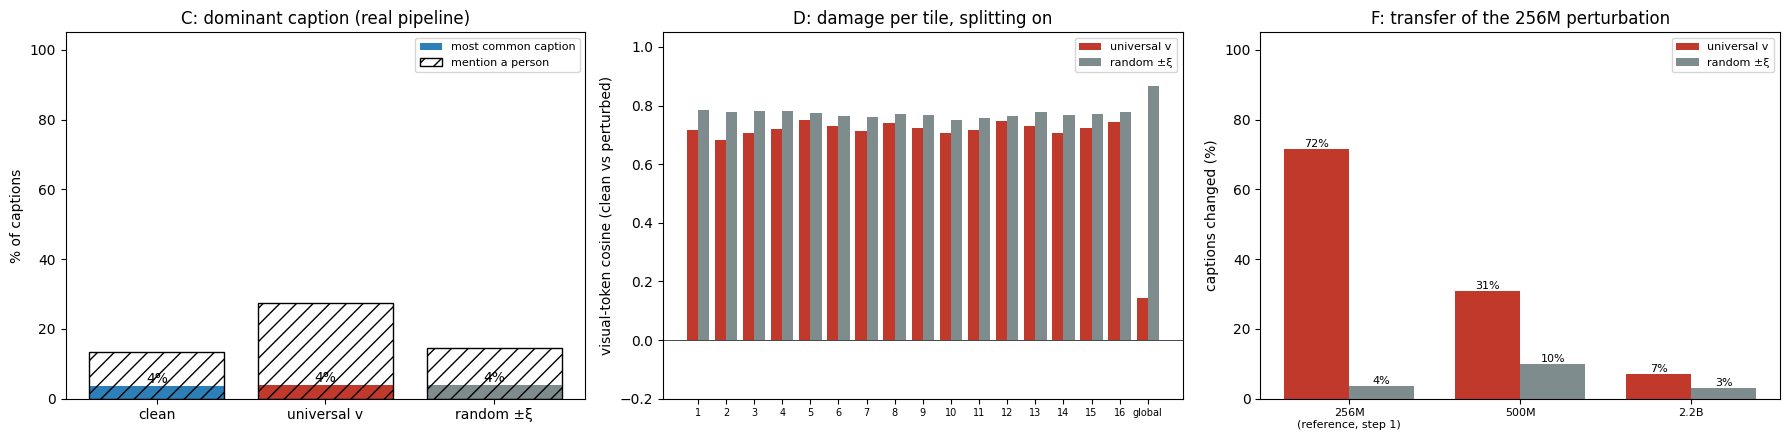

Saved /content/drive/MyDrive/uap_smolvlm/tiles_transfer_figures.png and /content/drive/MyDrive/uap_smolvlm/tiles_transfer_results.json


In [8]:
COL = {"universal v": "#c0392b", "random ±ξ": "#7f8c8d", "clean": "#2c7fb8"}
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))

# C: how concentrated are the captions?
C = RES["C_dominant"]; names = ["clean", "universal v", "random ±ξ"]
top_share = [C["summary"][n]["top_captions"][0][1] / C["n"] for n in names]
b = axs[0].bar(names, [100 * s for s in top_share], color=[COL[n] for n in names]); axs[0].bar_label(b, fmt="%.0f%%")
b2 = axs[0].bar(names, [100 * C["mentions_person"][n] for n in names], color="none", edgecolor="k", hatch="//", label="mention a person")
axs[0].set_ylabel("% of captions"); axs[0].set_ylim(0, 105); axs[0].legend(["most common caption", "mention a person"], fontsize=8)
axs[0].set_title("C: dominant caption (real pipeline)")

# D: per-tile damage
Dm = RES["D_tiles"]["mean_cos_per_tile"]; n_t = RES["D_tiles"]["n_tiles"]; x = np.arange(n_t)
for k, name in enumerate(["universal v", "random ±ξ"]):
    axs[1].bar(x + (k - .5) * .4, Dm[name], .4, color=COL[name], label=name)
axs[1].set_xticks(x, [str(i + 1) for i in range(n_t - 1)] + ["global"], fontsize=7)
axs[1].set_ylabel("visual-token cosine (clean vs perturbed)"); axs[1].set_ylim(-0.2, 1.05); axs[1].axhline(0, color="k", lw=.5)
axs[1].set_title("D: damage per tile, splitting on"); axs[1].legend(fontsize=8)

# F: transfer
T = RES["F_transfer"]; keys = list(T); x = np.arange(len(keys))
for k, name in enumerate(["universal v", "random ±ξ"]):
    b = axs[2].bar(x + (k - .5) * .38, [100 * T[m][name]["changed"] for m in keys], .38, color=COL[name], label=name)
    axs[2].bar_label(b, fmt="%.0f%%", fontsize=8)
axs[2].set_xticks(x, [m.replace(" (", "\n(") for m in keys], fontsize=8); axs[2].set_ylim(0, 105)
axs[2].set_ylabel("captions changed (%)"); axs[2].set_title("F: transfer of the 256M perturbation"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "tiles_transfer_figures.png", dpi=150); plt.show()
print("Saved", OUT / "tiles_transfer_figures.png", "and", OUT / "tiles_transfer_results.json")

In [9]:
import torch
from transformers import AutoModelForImageTextToText
get = lambda m: AutoModelForImageTextToText.from_pretrained(m).model.vision_model.state_dict()
a, b = get("HuggingFaceTB/SmolVLM-256M-Instruct"), get("HuggingFaceTB/SmolVLM-500M-Instruct")
shared = [k for k in a if k in b and a[k].shape == b[k].shape]
rel = sorted(((a[k].float() - b[k].float()).norm() / (a[k].float().norm() + 1e-12)).item() for k in shared)
print(f"tensors: 256M {len(a)}, 500M {len(b)}, same name+shape {len(shared)}")
print(f"identical: {sum(r == 0 for r in rel)} | median relative difference: {rel[len(rel)//2]:.3f}")

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

tensors: 256M 197, 500M 197, same name+shape 197
identical: 0 | median relative difference: 0.019
